# Public health analysis — Country comparison

Averages tell you where the world is going; the country view tells you who's driving and who's being left behind. Three things in this notebook:

1. **Rankings** — who lives longest today (and the methodological guard-rails that keep microstates from dominating the list),
2. **Movers since 1990** — the biggest gains and the short, bleak list of declines,
3. **Spotlight trajectories** — ten countries, seventy years, one scale.

Reads `../data/processed/panel.csv` from [data_wrangling.ipynb](data_wrangling.ipynb).

In [1]:
# Setup block -- same as the other notebooks so each one runs on its own.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D8DEE4", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.labelsize": 10.5, "axes.labelcolor": "#4A5560",
    "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.titlepad": 14, "axes.titlecolor": "#1A2530",
    "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.dpi": 110, "savefig.dpi": 200,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

REGION_COLORS = {
    "Africa": "#EE7733",
    "Asia": "#0077BB",
    "Europe": "#009988",
    "North America": "#33BBEE",
    "South America": "#CC3311",
    "Oceania": "#EE3377",
}
NEUTRAL, NEUTRAL_LIGHT, GRID = "#4A5560", "#9AA7B2", "#E8EDF1"
SOURCE_NOTE = ("Source: Our World in Data (UN WPP 2024, UN IGME 2024, World Bank, "
               "WHO GHO, IHME GBD, Maddison Project). CC BY 4.0.")

def headline(ax, title, subtitle=None):
    ax.set_title(title, loc="left", pad=34 if subtitle else 14)
    if subtitle:
        ax.text(0, 1.045, subtitle, transform=ax.transAxes,
                fontsize=10, color=NEUTRAL, va="bottom")

def clean_axis(ax, grid=True, axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if grid:
        ax.grid(axis=axis, color=GRID, linewidth=0.7)
        ax.set_axisbelow(True)

def save(fig, name, note=SOURCE_NOTE):
    if note:
        fig.text(0.006, 0.008, note, fontsize=7.5, color=NEUTRAL_LIGHT, va="bottom")
        try:
            fig.get_layout_engine().set(rect=(0, 0.042, 1, 0.958))
        except Exception:
            pass
    path = f"../figures/{name}.png"
    fig.savefig(path, dpi=200, facecolor="white")
    plt.show()
    print("saved", path)

def latest_snapshot(df, value, window=5):
    """Each country's most recent value of `value`, taken within `window`
    years of the indicator's own latest year. Anchoring at the indicator's
    own frontier matters: air pollution ends in 2019, GDP in 2022, life
    expectancy in 2023 -- a window anchored at 2024 would silently return
    nothing for the older series. The reference year travels with the value
    so no figure has to pretend all data is from the same year."""
    el = df.dropna(subset=[value])
    anchor = int(el["year"].max())
    el = el[el["year"].between(anchor - window + 1, anchor)]
    snap = (el.sort_values("year")
              .groupby("country", as_index=False)
              .tail(1)
              .rename(columns={"year": "ref_year", value: "value"}))
    cols = ["country", "iso3", "region", "ref_year", "value"]
    if "population" in snap.columns and value != "population":
        cols.append("population")
    return snap[cols]

def endpoint_movers(df, value, start_year, end_year, min_population=0, population_year=2023):
    """Change in `value` between start_year and the latest available year
    (searched in [end_year - 3, end_year] -- publishing schedules differ, and
    dropping a country because its 2024 value isn't out yet would bias the
    comparison)."""
    recent = df[df["year"].between(end_year - 3, end_year)]
    end = (recent.dropna(subset=[value])
           .sort_values("year")
           .groupby("country")
           .tail(1)[["country", "region", "year", value]]
           .rename(columns={"year": "end_year", value: "end_value"}))
    start = (df[df["year"] == start_year]
             .dropna(subset=[value])[["country", value]]
             .rename(columns={value: "start_value"}))
    m = start.merge(end, on="country")
    m["change"] = m["end_value"] - m["start_value"]
    if min_population:
        pop = df[df["year"] == population_year][["country", "population"]]
        m = m.merge(pop, on="country", how="left")
        m = m[m["population"].fillna(0) >= min_population]
    return m.sort_values("change", ascending=False).reset_index(drop=True)

panel = pd.read_csv("../data/processed/panel.csv")
print(f"{panel.country.nunique()} countries · {len(panel):,} rows")

248 countries · 18,273 rows


## 1. Who lives longest today

Two guard-rails before any ranking is worth showing:

- **Microstates stay out of the rankings.** Every cross-country list in this project filters to countries above 500k people. Monaco's life expectancy is a real number, but health statistics with four-digit denominators swing for reasons that have nothing to do with policy, and "Monaco tops the list" tells a policymaker nothing. (Small countries stay in every other analysis — this filter is only for top/bottom tables.)
- **"Latest" is a window, not a year.** Each country contributes its most recent value within two years of the indicator's frontier, and the reference year is kept next to the value — because a 2023 value and a 2022 value are close enough to compare, while hard-coding "2023" would silently drop every late publisher.

In [2]:
# latest_snapshot carries the population from the same row (same vintage) --
# exactly what I want for the size filter
snap = latest_snapshot(panel, "life_expectancy", window=2)
snap = snap[snap["population"].fillna(0) >= 500_000]

movers = endpoint_movers(panel, "life_expectancy", 1990, 2024,
                         min_population=500_000, population_year=2023)

rankings = (snap.sort_values("value", ascending=False)
            .reset_index(drop=True)
            .merge(movers[["country", "start_value", "change"]], on="country", how="left"))
rankings.insert(0, "rank", rankings.index + 1)
rankings = rankings.rename(columns={"value": "life_expectancy",
                                    "start_value": "le_1990",
                                    "change": "change_since_1990"})
rankings = rankings[["rank", "country", "region", "ref_year", "life_expectancy",
                     "le_1990", "change_since_1990"]]
rankings.to_csv("../data/processed/le_rankings.csv", index=False)
print(f"{len(rankings)} countries ranked (>=500k population)")
rankings.head(15)

175 countries ranked (>=500k population)


,rank,country,region,ref_year,life_expectancy,le_1990,change_since_1990
0,1,Hong Kong,Asia,2023,85.5106,77.4481,8.0625
1,2,Japan,Asia,2023,84.7123,78.9928,5.7195
2,3,South Korea,Asia,2023,84.3288,70.9936,13.3352
3,4,Switzerland,Europe,2023,83.9536,77.3851,6.5685
4,5,Australia,Oceania,2023,83.9228,77.0414,6.8814
5,6,Singapore,Asia,2023,83.7362,74.5982,9.1380
6,7,Italy,Europe,2023,83.7157,76.9936,6.7221
7,8,Spain,Europe,2023,83.6703,77.0004,6.6699
8,9,Reunion,Africa,2023,83.5472,74.1895,9.3577
9,10,France,Europe,2023,83.3253,76.8351,6.4902


In [3]:
rankings.tail(10)

,rank,country,region,ref_year,life_expectancy,le_1990,change_since_1990
165,166,Burkina Faso,Africa,2023,61.0920,49.3145,11.7775
166,167,Benin,Africa,2023,60.7738,53.0205,7.7533
167,168,Guinea,Africa,2023,60.7405,47.2518,13.4887
168,169,Mali,Africa,2023,60.4394,46.5415,13.8979
169,170,Somalia,Africa,2023,58.8158,46.8960,11.9198
170,171,South Sudan,Africa,2023,57.6174,28.6275,28.9899
171,172,Central African Republic,Africa,2023,57.4077,49.8543,7.5534
172,173,Lesotho,Africa,2023,57.3749,59.3171,-1.9422
173,174,Chad,Africa,2023,55.0692,45.0738,9.9954
174,175,Nigeria,Africa,2023,54.4623,45.7327,8.7296


The top of the table is East Asia and Europe's edge cases (Hong Kong 85.5, Japan 84.7, South Korea 84.3 — all 2023); the bottom is the Sahel and southern Africa, in the mid-50s. A gap of more than 30 years between the extremes is the single number I'd keep from this table.

Two honest footnotes: several top entries' statistics are for territories with special administrative status, and — more importantly — life expectancy for much of the bottom of the list is **modelled** by the UN (partial or absent vital registration), so the ranking's tail is an estimate with real uncertainty around it. That doesn't change the picture; it changes how many decimal places you're allowed to quote.

## 2. Movers since 1990

Same value, different question: not *where* countries are, but how far they've come. The end point is each country's latest value — which for most of the world now includes the COVID years, so part of every "change since 1990" is the pandemic. That's inherent to asking the question in 2024, and it cuts against the recoveries, not for them.

In [4]:
movers = endpoint_movers(panel, "life_expectancy", 1990, 2024,
                         min_population=500_000, population_year=2023)
print(f"{len(movers)} countries with data at both ends")
movers.head(10)[["country", "region", "start_value", "end_value", "end_year", "change"]]

175 countries with data at both ends


,country,region,start_value,end_value,end_year,change
0,South Sudan,Africa,28.6275,57.6174,2023,28.9899
1,Liberia,Africa,37.6435,62.1625,2023,24.5190
2,Malawi,Africa,43.5748,67.3535,2023,23.7787
3,Angola,Africa,41.8542,64.6170,2023,22.7628
4,East Timor,Asia,45.1849,67.6894,2023,22.5045
5,Ethiopia,Africa,45.1166,67.3150,2023,22.1984
6,Afghanistan,Asia,45.1183,66.0346,2023,20.9163
7,Uganda,Africa,47.5612,68.2523,2023,20.6911
8,Rwanda,Africa,47.7629,67.7852,2023,20.0223
9,Niger,Africa,41.7324,61.1833,2023,19.4509


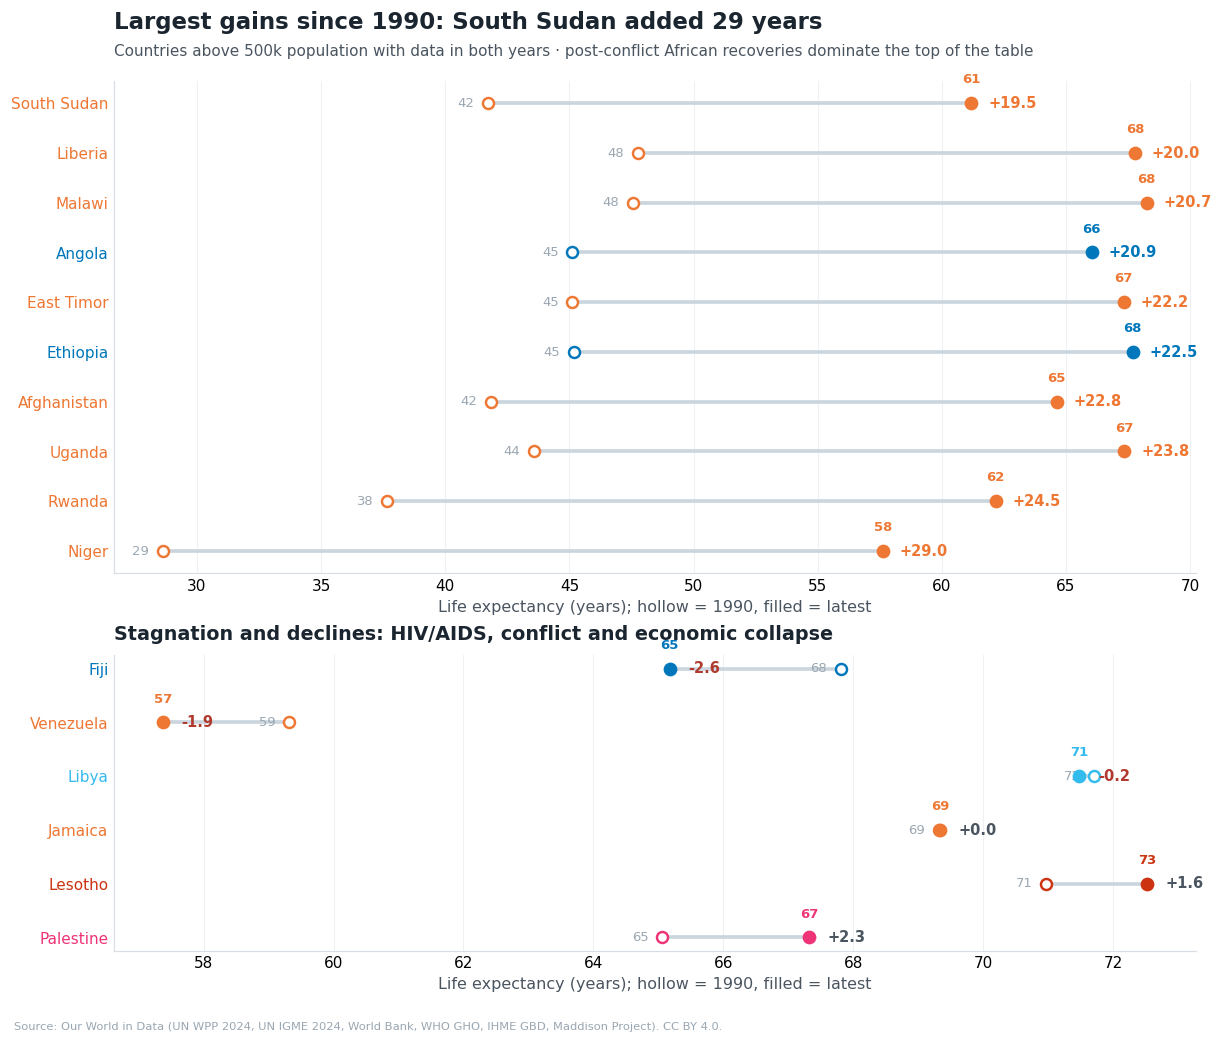

saved ../figures/le_movers_dumbbell.png


In [5]:
top = movers.head(10).iloc[::-1]        # reversed so the biggest gain reads first, top-down
bottom = movers.tail(6).sort_values("change")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9.4), constrained_layout=True,
                               gridspec_kw={"height_ratios": [10, 6]})

def dumbbell(ax, data, show_change=True):
    for i, (_, row) in enumerate(data.iterrows()):
        y = len(data) - 1 - i
        color = REGION_COLORS.get(row["region"], NEUTRAL)
        ax.plot([row["start_value"], row["end_value"]], [y, y],
                color="#CBD5DD", linewidth=2.4, zorder=2)
        ax.scatter(row["start_value"], y, s=52, facecolor="white",
                   edgecolor=color, linewidth=1.6, zorder=3)
        ax.scatter(row["end_value"], y, s=64, color=color, zorder=4)
        # start value to the left, end value above the dot: when a country's
        # two dots nearly coincide (Libya: +0.0 years in 33 years) the labels
        # stay readable instead of stacking on the same spot
        ax.annotate(f"{row['start_value']:.0f}", (row["start_value"], y),
                    xytext=(-9, 0), textcoords="offset points",
                    ha="right", va="center", fontsize=8.6, color=NEUTRAL_LIGHT)
        ax.annotate(f"{row['end_value']:.0f}", (row["end_value"], y),
                    xytext=(0, 13), textcoords="offset points",
                    ha="center", fontsize=8.6, color=color, fontweight="bold")
        if show_change:
            ax.annotate(f"+{row['change']:.1f}", (row["end_value"], y),
                        xytext=(11, 0), textcoords="offset points",
                        va="center", fontsize=9.6, color=color, fontweight="bold")
    ax.set_yticks(range(len(data)))
    ax.set_yticklabels(list(data["country"]), fontsize=10)
    for tick, (_, row) in zip(ax.get_yticklabels(), data.iloc[::-1].iterrows()):
        tick.set_color(REGION_COLORS.get(row["region"], NEUTRAL))
    ax.set_xlabel("Life expectancy (years); hollow = 1990, filled = latest")
    clean_axis(ax, grid=False, axis="x")
    ax.xaxis.grid(True, color="#EDF1F4", linewidth=0.7)
    ax.set_axisbelow(True)

dumbbell(ax1, top)
dumbbell(ax2, bottom, show_change=False)
for _, row in bottom.iterrows():
    y = len(bottom) - 1 - list(bottom["country"]).index(row["country"])
    ax2.annotate(f"{row['change']:+.1f}", (row["end_value"], y),
                 xytext=(12, 0), textcoords="offset points", va="center",
                 fontsize=9.6, color="#B03A2E" if row["change"] < 0 else NEUTRAL,
                 fontweight="bold")

top_gain = movers.iloc[0]
headline(ax1, f"Largest gains since 1990: {top_gain['country']} added {top_gain['change']:.0f} years",
         "Countries above 500k population with data in both years · post-conflict African "
         "recoveries dominate the top of the table")
ax2.set_title("Stagnation and declines: HIV/AIDS, conflict and economic collapse",
              loc="left", fontsize=12.5, pad=10)
save(fig, "le_movers_dumbbell")

The two panels tell the two halves of the story:

- **The top is Africa.** South Sudan (+29.0), Liberia (+24.5), Malawi (+23.8), Angola (+22.8), East Timor (+22.5), Ethiopia (+22.2), Afghanistan (+20.9) — countries rebuilding health systems after war, plus the African recovery from the HIV/AIDS era as antiretroviral therapy rolled out. Where 1990 was the floor, the gains since are extraordinary.
- **The decliners are few and explicable.** Palestine (−2.6) and Lesotho (−1.9) — conflict and the tail of the HIV epidemic. Jamaica (−0.2) is the genuine long-run puzzle it's always been. Libya (+0.0 in 33 years) is civil war. Nobody on this list declined because their health system quietly got worse at its job; the list is shocks.

For the record: these are *observed* recoveries, not forecasts. The same countries top this list precisely because they started at the bottom — mean reversion does some of the work, and any causal reading (what "caused" South Sudan's +29?) needs the confounders of a starting point near the floor.

## 3. Spotlight: ten countries, seventy years

The dumbbell compresses each country to two dots. These small multiples give the full trajectories — the same ten countries I keep coming back to in this project: big, regionally spread, and each with a story worth knowing.

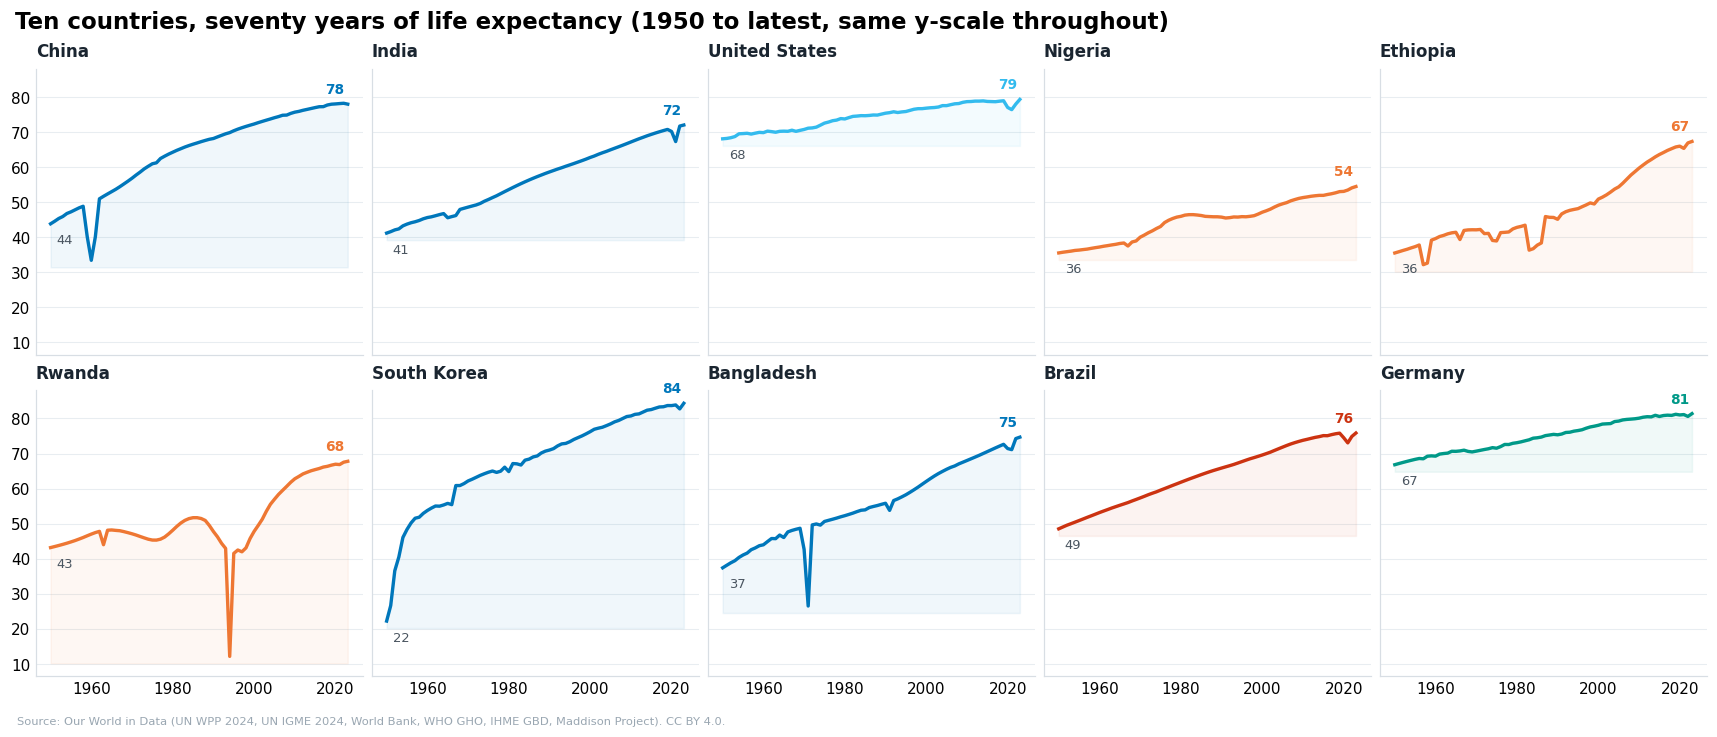

saved ../figures/spotlight_life_expectancy.png


In [6]:
SPOTLIGHT = ["China", "India", "United States", "Nigeria", "Ethiopia",
             "Rwanda", "South Korea", "Bangladesh", "Brazil", "Germany"]

fig, axes = plt.subplots(2, 5, figsize=(15.5, 6.6), constrained_layout=True,
                         sharex=True, sharey=True)
for ax, country in zip(axes.flat, SPOTLIGHT):
    s = (panel[(panel["country"] == country) & panel["life_expectancy"].notna()]
         .sort_values("year"))
    color = REGION_COLORS.get(s["region"].iloc[0], NEUTRAL)
    ax.plot(s["year"], s["life_expectancy"], color=color, linewidth=2.2, zorder=3)
    ax.fill_between(s["year"], s["life_expectancy"], s["life_expectancy"].min() - 2,
                    color=color, alpha=0.06, zorder=1)
    first, last = s.iloc[0], s.iloc[-1]
    ax.annotate(f"{first.life_expectancy:.0f}", (first.year, first.life_expectancy),
                xytext=(4, -13), textcoords="offset points",
                fontsize=8.5, color=NEUTRAL)
    ax.annotate(f"{last.life_expectancy:.0f}", (last.year, last.life_expectancy),
                xytext=(-2, 7), textcoords="offset points", ha="right",
                fontsize=9, color=color, fontweight="bold")
    ax.set_title(country, fontsize=11, pad=8, loc="left")
    clean_axis(ax)

fig.suptitle("Ten countries, seventy years of life expectancy (1950 to latest, same y-scale throughout)",
             x=0.005, ha="left", fontsize=15, fontweight="bold")
save(fig, "spotlight_life_expectancy")

Same scale, seventy years, very different journeys:

- **China** went from ~44 to ~78 years — one of the fastest sustained climbs ever recorded, and the single biggest driver of the *world* average.
- **Ethiopia and Rwanda** climb later but steeper; Rwanda's 1994 notch (the genocide, visible as the dip around year 44 of the x-axis) is the sharpest single-year shock in the whole panel.
- **The United States** is the flat-line story: roughly 20 years of gains, then a plateau from the mid-2010s at ~77–79 that predates COVID — the observation that anchors most US health-policy debates.
- **Germany** shows what the frontier's second half looks like: steady, slow, and hard-won.

## Recap

The country view turns "the world is healthier" into concrete narratives: African post-conflict recoveries own the top of the gains table, a handful of shock-struck countries own the bottom, and the plateau at the rich-country frontier is now visible without any statistics at all.

Next: **[child_survival.ipynb](child_survival.ipynb)** — under-five mortality, where the global divide is sharpest.